# Практична робота 8.1
## Нейронні мережі в розпізнаванні образів. Частина 2


In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout

seed_value = 1234578790
tf.keras.utils.set_random_seed(seed_value)


### 0. Перегляд даних
CIFAR-10 містить кольорові зображення розміром 32 × 32 пікселі десяти класів.


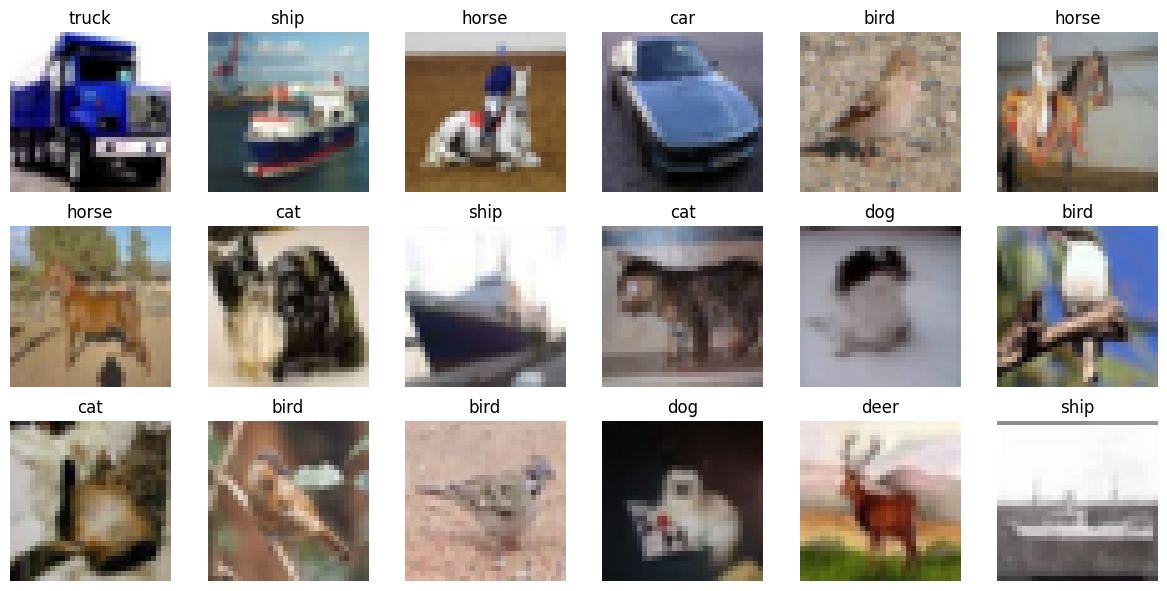

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
y_train = y_train.ravel()
y_test = y_test.ravel()
classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
num_classes = len(classes)

rng = np.random.default_rng(seed_value)
indices = rng.choice(len(x_train), 18, replace=False)
fig, axes = plt.subplots(3, 6, figsize=(12, 6))
for ax, idx in zip(axes.flat, indices):
    ax.imshow(x_train[idx])
    ax.set_title(classes[y_train[idx]])
    ax.axis('off')
plt.tight_layout()
plt.show()

In [3]:
train_counts = np.bincount(y_train, minlength=num_classes)
for class_id, class_name in enumerate(classes):
    print(class_name, train_counts[class_id])
print('Balanced dataset:', bool(np.all(train_counts == train_counts[0])))


plane 5000
car 5000
bird 5000
cat 5000
deer 5000
dog 5000
frog 5000
horse 5000
ship 5000
truck 5000
Balanced dataset: True


### 1. Підготовка даних
Значення пікселів нормалізовано до діапазону [0; 1], а мітки класів перетворено на one-hot вектори. 


In [4]:
# Normalization
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# One-hot encoding
y_train = tf.keras.utils.to_categorical(y_train, num_classes)
y_test = tf.keras.utils.to_categorical(y_test, num_classes)

print('Train set:   ', len(y_train), 'samples')
print('Test set:    ', len(y_test), 'samples')
print('Sample dims: ', x_train.shape)


Train set:    50000 samples
Test set:     10000 samples
Sample dims:  (50000, 32, 32, 3)


### 2. Побудова класифікатора
Беру структуру з прикладу MNIST: два згорткові шари з 16 і 32 фільтрами та ядрами 3 × 3. Шари MaxPooling зменшують просторові розміри карт ознак, а Flatten перетворює їх на вектор. Вихідний шар із функцією softmax визначає ймовірності належності зображення до кожного з десяти класів.

In [5]:
def build_model(use_dropout=False):
    inputs = Input(shape=(32, 32, 3))
    net = Conv2D(16, (3, 3), activation='relu')(inputs)
    net = MaxPooling2D((2, 2))(net)
    net = Conv2D(32, (3, 3), activation='relu')(net)
    net = MaxPooling2D((2, 2))(net)
    net = Flatten()(net)
    if use_dropout:
        net = Dropout(0.3)(net)
    outputs = Dense(num_classes, activation='softmax')(net)
    return Model(inputs, outputs)

model = build_model()
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 30, 30, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        11,530 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,618 (64.91 KB)

 Trainable params: 16,618 (64.91 KB)

 Non-trainable params: 0 (0.00 B)

### 3. Навчання
Використовую оптимізатор Adam і функцію втрат categorical cross-entropy, оскільки маю десять класів та one-hot мітки. Відповідно до шаблону, кількість епох становить 25, а розмір пакета — 128 зображень.
Під час навчання 10% навчальної вибірки виділено для валідації.

In [6]:
epochs = 25
batch_size = 128
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
history = model.fit(x_train, y_train, validation_split=0.1,
                    epochs=epochs, batch_size=batch_size, verbose=2)


Epoch 1/25
352/352 - 7s - 21ms/step - accuracy: 0.3862 - loss: 1.7168 - val_accuracy: 0.4542 - val_loss: 1.5333
Epoch 2/25
352/352 - 5s - 15ms/step - accuracy: 0.5103 - loss: 1.3941 - val_accuracy: 0.4958 - val_loss: 1.4289
Epoch 3/25
352/352 - 5s - 15ms/step - accuracy: 0.5500 - loss: 1.2913 - val_accuracy: 0.5366 - val_loss: 1.3091
Epoch 4/25
352/352 - 5s - 15ms/step - accuracy: 0.5772 - loss: 1.2176 - val_accuracy: 0.5786 - val_loss: 1.2060
Epoch 5/25
352/352 - 5s - 15ms/step - accuracy: 0.5992 - loss: 1.1597 - val_accuracy: 0.6008 - val_loss: 1.1386
Epoch 6/25
352/352 - 5s - 15ms/step - accuracy: 0.6157 - loss: 1.1141 - val_accuracy: 0.6166 - val_loss: 1.0975
Epoch 7/25
352/352 - 6s - 16ms/step - accuracy: 0.6293 - loss: 1.0781 - val_accuracy: 0.6328 - val_loss: 1.0687
Epoch 8/25
352/352 - 6s - 17ms/step - accuracy: 0.6398 - loss: 1.0486 - val_accuracy: 0.6414 - val_loss: 1.0469
Epoch 9/25
352/352 - 6s - 17ms/step - accuracy: 0.6491 - loss: 1.0233 - val_accuracy: 0.6514 - val_loss:

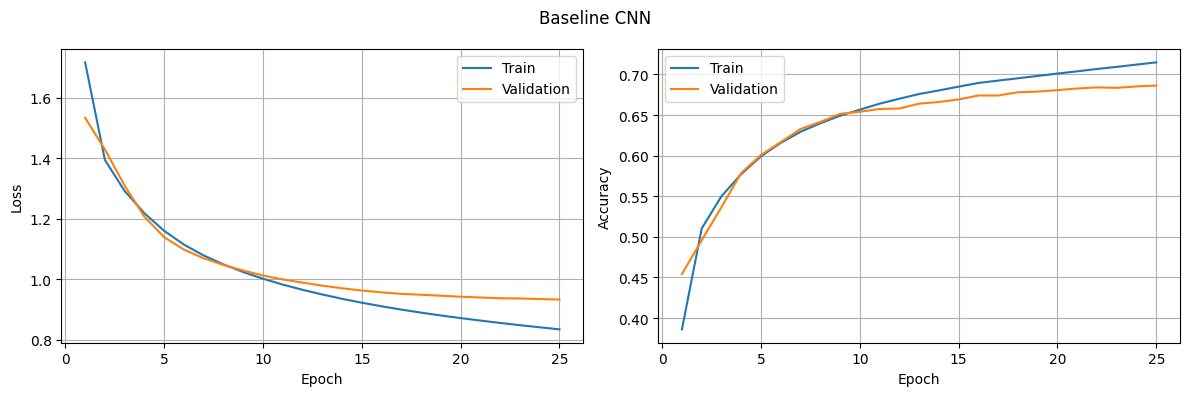

Train accuracy: 71.48%
Validation accuracy: 68.62%


In [7]:
def plot_history(history, title):
    h = history.history
    epoch_numbers = np.arange(1, len(h['loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric, label in zip(axes, ['loss', 'accuracy'], ['Loss', 'Accuracy']):
        ax.plot(epoch_numbers, h[metric], label='Train')
        ax.plot(epoch_numbers, h['val_' + metric], label='Validation')
        ax.set_xlabel('Epoch')
        ax.set_ylabel(label)
        ax.grid(True)
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
    print(f"Train accuracy: {h['accuracy'][-1]:.2%}")
    print(f"Validation accuracy: {h['val_accuracy'][-1]:.2%}")

plot_history(history, 'Baseline CNN')

### 4. Оцінювання на тестовій вибірці

In [12]:
y_true = np.argmax(y_test, axis=1)
y_pred = np.argmax(model.predict(x_test, batch_size=batch_size, verbose=0), axis=1)

base_class_acc = []

for class_id, class_name in enumerate(classes):
    mask = y_true == class_id
    acc = np.mean(y_pred[mask] == y_true[mask])
    base_class_acc.append(acc)
    print(f'{class_name:6s}: {acc:.2%}')
base_loss, base_acc = model.evaluate(x_test, y_test, batch_size=batch_size, verbose=0)
print()
print(f'Test loss: {base_loss:.4f}')
print(f'Test accuracy: {base_acc:.2%}')

plane : 72.40%
car   : 78.30%
bird  : 53.60%
cat   : 45.90%
deer  : 67.70%
dog   : 60.30%
frog  : 74.00%
horse : 72.50%
ship  : 66.80%
truck : 79.90%

Test loss: 0.9750
Test accuracy: 67.14%


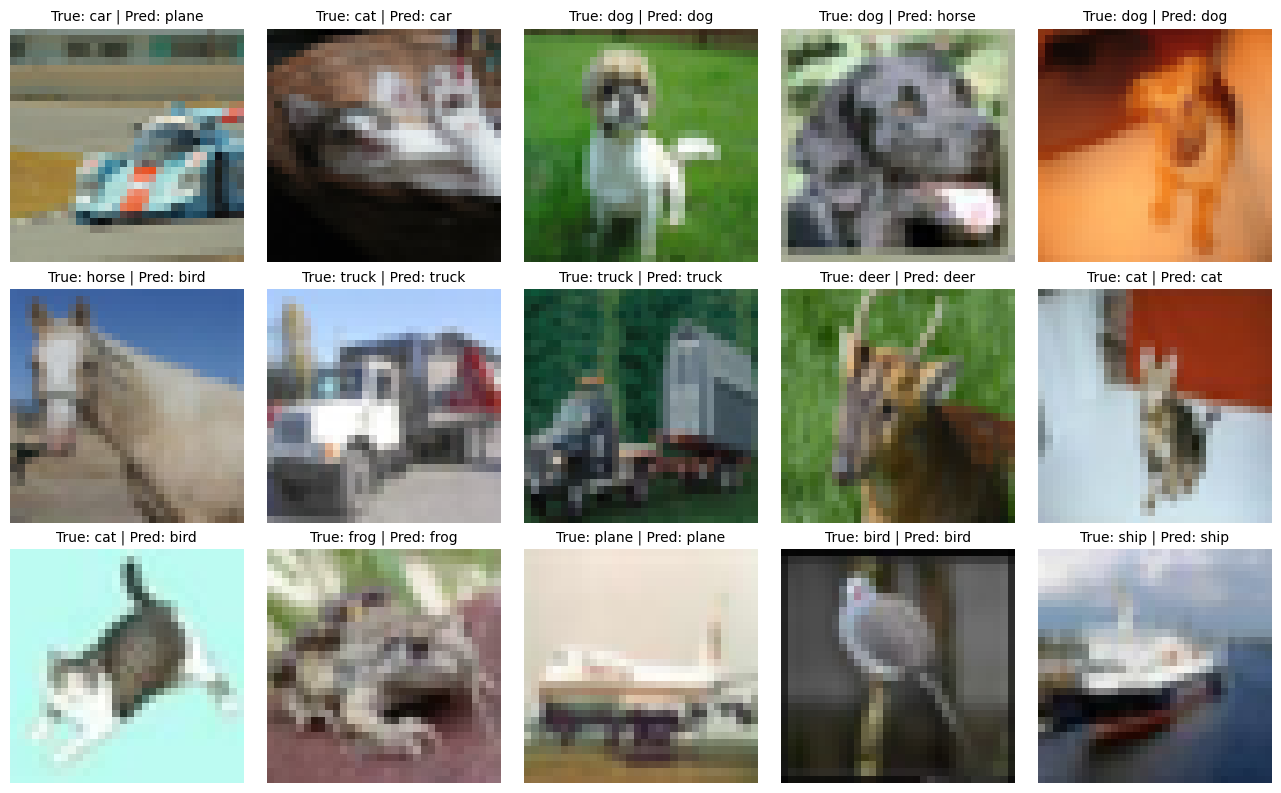

In [9]:
indices = rng.choice(len(x_test), 15, replace=False)
fig, axes = plt.subplots(3, 5, figsize=(13, 8))
for ax, idx in zip(axes.flat, indices):
    ax.imshow(x_test[idx])
    ax.set_title(f'True: {classes[y_true[idx]]} | Pred: {classes[y_pred[idx]]}', fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()


### 5. Одна зміна та повторне навчання
Додаю лише Dropout із часткою 0.3 перед вихідним шаром. Під час навчання він випадково вимикає 30% елементів вектора ознак для зменшення перенавчання. Інші шари, вибірки, кількість епох, оптимізатор і розмір пакета залишаю такими самими. Нову модель навчаю з початку.

In [10]:
tf.keras.utils.set_random_seed(seed_value)
improved_model = build_model(use_dropout=True)
improved_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
improved_history = improved_model.fit(x_train, y_train, validation_split=0.1,
                                      epochs=epochs, batch_size=batch_size, verbose=2)


Epoch 1/25
352/352 - 8s - 24ms/step - accuracy: 0.3785 - loss: 1.7237 - val_accuracy: 0.4584 - val_loss: 1.5300
Epoch 2/25
352/352 - 6s - 17ms/step - accuracy: 0.4970 - loss: 1.4216 - val_accuracy: 0.5014 - val_loss: 1.4168
Epoch 3/25
352/352 - 6s - 17ms/step - accuracy: 0.5341 - loss: 1.3328 - val_accuracy: 0.5356 - val_loss: 1.3268
Epoch 4/25
352/352 - 6s - 16ms/step - accuracy: 0.5575 - loss: 1.2705 - val_accuracy: 0.5706 - val_loss: 1.2237
Epoch 5/25
352/352 - 6s - 16ms/step - accuracy: 0.5747 - loss: 1.2219 - val_accuracy: 0.5946 - val_loss: 1.1680
Epoch 6/25
352/352 - 6s - 17ms/step - accuracy: 0.5876 - loss: 1.1823 - val_accuracy: 0.6162 - val_loss: 1.1136
Epoch 7/25
352/352 - 6s - 16ms/step - accuracy: 0.5984 - loss: 1.1536 - val_accuracy: 0.6310 - val_loss: 1.0809
Epoch 8/25
352/352 - 6s - 16ms/step - accuracy: 0.6067 - loss: 1.1263 - val_accuracy: 0.6416 - val_loss: 1.0495
Epoch 9/25
352/352 - 6s - 17ms/step - accuracy: 0.6169 - loss: 1.1035 - val_accuracy: 0.6478 - val_loss:

In [11]:
improved_loss, improved_acc = improved_model.evaluate(x_test, y_test,
                                                      batch_size=batch_size, verbose=0)
print(f'Baseline accuracy: {base_acc:.2%}')
print(f'Dropout accuracy: {improved_acc:.2%}')


Baseline accuracy: 67.14%
Dropout accuracy: 68.24%
